# Module 06: Gradient Descent, Optimizers, and Learning-Rate Strategy

This module teaches how neural networks actually improve their weights after backpropagation calculates gradients. The goal is not to memorize optimizer names. The goal is to understand what problem each optimizer solves, how the update is calculated, what the visualization looks like, and what failure signs appear during training.

The module uses two datasets:

* a **synthetic loss surface** so optimizer movement can be visualized clearly;
* a **mini-batch regression dataset** so batch gradients, noisy SGD, learning-rate schedules, and clipping can be shown with real calculations.


## Module outline

* **Step 1: Loss Surface and Gradient Direction**
  * loss surface, parameter space, gradient vector, steep direction, contour plot.
* **Step 2: Gradient Descent Update**
  * update rule, learning rate, one-step calculation, why update moves opposite the gradient.
* **Step 3: Batch GD, SGD, and Mini-Batch GD**
  * full gradient, one-example gradient, mini-batch gradient, gradient noise, epoch vs iteration.
* **Step 4: Learning Rate Behavior**
  * too small, useful, too large, exploding loss, learning-rate range intuition.
* **Step 5: Momentum**
  * velocity, damped zig-zagging, ravine problem, calculation table.
* **Step 6: Nesterov Momentum**
  * look-ahead point, correction before overshoot, difference from classical momentum.
* **Step 7: AdaGrad**
  * accumulated squared gradients, per-parameter learning rate, sparse-feature intuition, shrinking-step problem.
* **Step 8: RMSProp**
  * moving average of squared gradients, fix for AdaGrad shrinking, coordinate scaling.
* **Step 9: Adam and AdamW**
  * first moment, second moment, bias correction, Adam as momentum + RMSProp, decoupled weight decay.
* **Step 10: Learning-Rate Schedules**
  * step decay, exponential decay, cosine decay, cyclic LR, OneCycle, ReduceLROnPlateau.
* **Step 11: Warmup**
  * why early updates can be unstable, linear warmup, warmup + cosine decay.
* **Step 12: Gradient Clipping**
  * exploding gradients, norm clipping, value clipping, calculation example, when clipping is a symptom.
* **Step 13: Optimizer Selection Workflow**
  * when to start with SGD, AdamW, schedules, clipping, and diagnostics.


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

plt.rcParams['figure.figsize'] = (8, 5)
plt.rcParams['axes.grid'] = True
plt.rcParams['font.size'] = 10
rng = np.random.default_rng(42)


## Dataset and Visualization Setup

Optimizer behavior is difficult to understand directly inside a large neural network because the loss surface has millions of dimensions. So this module first uses a two-parameter loss surface:

$$L(w_1,w_2)=0.1(w_1-3)^2+2(w_2+1)^2$$

This surface has one shallow direction and one steep direction. That creates the common **ravine problem**: the optimizer can move slowly in one direction while bouncing in the steep direction.

The minimum is at:

$$w_1=3, \quad w_2=-1$$


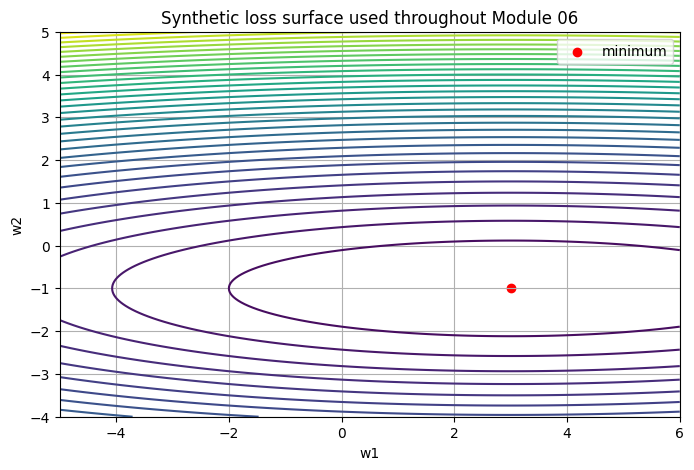

In [2]:
def loss_fn(w):
    w = np.asarray(w)
    return 0.1*(w[...,0]-3)**2 + 2.0*(w[...,1]+1)**2

def grad_fn(w):
    w = np.asarray(w)
    return np.array([0.2*(w[0]-3), 4.0*(w[1]+1)])

x = np.linspace(-5, 6, 220)
y = np.linspace(-4, 5, 220)
X, Y = np.meshgrid(x, y)
Z = loss_fn(np.stack([X, Y], axis=-1))
plt.contour(X, Y, Z, levels=35)
plt.scatter([3], [-1], c='red', label='minimum')
plt.title('Synthetic loss surface used throughout Module 06')
plt.xlabel('w1'); plt.ylabel('w2'); plt.legend();


## Step 1: Loss Surface and Gradient Direction

**What is it?** A loss surface shows how the loss changes for different parameter values. In a real neural network the parameter space may have millions or billions of dimensions, but the idea is the same: every point is one possible set of weights, and the height is the loss.

**Gradient meaning:** the gradient is a vector of partial derivatives. It points in the direction where loss increases fastest.

$$\nabla L = \left[\frac{\partial L}{\partial w_1}, \frac{\partial L}{\partial w_2}\right]$$

For the synthetic surface:

$$\frac{\partial L}{\partial w_1}=0.2(w_1-3)$$
$$\frac{\partial L}{\partial w_2}=4(w_2+1)$$

**Why it matters:** optimizers do not know the full shape of the surface. They only receive local gradient information and must decide how to step.


current parameters: [-3.  3.]
current loss: 35.6
gradient: [-1.2 16. ]
negative gradient direction: [  1.2 -16. ]


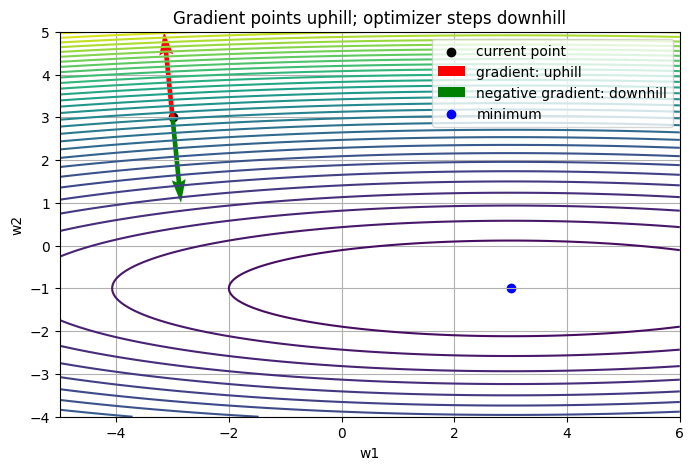

In [3]:
w = np.array([-3.0, 3.0])
g = grad_fn(w)
print('current parameters:', w)
print('current loss:', round(loss_fn(w), 3))
print('gradient:', g)
print('negative gradient direction:', -g)

plt.contour(X, Y, Z, levels=35)
plt.scatter([w[0]], [w[1]], c='black', label='current point')
plt.quiver(w[0], w[1], g[0], g[1], color='red', angles='xy', scale_units='xy', scale=8, label='gradient: uphill')
plt.quiver(w[0], w[1], -g[0], -g[1], color='green', angles='xy', scale_units='xy', scale=8, label='negative gradient: downhill')
plt.scatter([3], [-1], c='blue', label='minimum')
plt.title('Gradient points uphill; optimizer steps downhill')
plt.xlabel('w1'); plt.ylabel('w2'); plt.legend();


## Step 2: Gradient Descent Update

**What is it?** Gradient descent updates parameters by moving opposite the gradient.

$$w_{new}=w_{old}-\eta\nabla L(w_{old})$$

where $\eta$ is the learning rate.

**Calculation example:** At $w=[-3,3]$:

$$\nabla L=[-1.2,16]$$

With learning rate $\eta=0.1$:

$$w_{new}=[-3,3]-0.1[-1.2,16]=[-2.88,1.4]$$

The second coordinate changes a lot because the surface is much steeper in that direction.


In [4]:
w_old = np.array([-3.0, 3.0])
eta = 0.1
g = grad_fn(w_old)
w_new = w_old - eta*g
display(pd.DataFrame({
    'quantity':['w_old','gradient','eta * gradient','w_new'],
    'w1':[w_old[0], g[0], eta*g[0], w_new[0]],
    'w2':[w_old[1], g[1], eta*g[1], w_new[1]]
}))
print('old loss:', round(loss_fn(w_old), 4))
print('new loss:', round(loss_fn(w_new), 4))


,quantity,w1,w2
0,w_old,-3.00,3.0
1,gradient,-1.20,16.0
2,eta * gradient,-0.12,1.6
3,w_new,-2.88,1.4


old loss: 35.6
new loss: 14.9774


**Common mistake:** thinking the optimizer moves directly to the minimum. It only takes one local step. Many steps are needed, and bad step sizes can make the path slow or unstable.


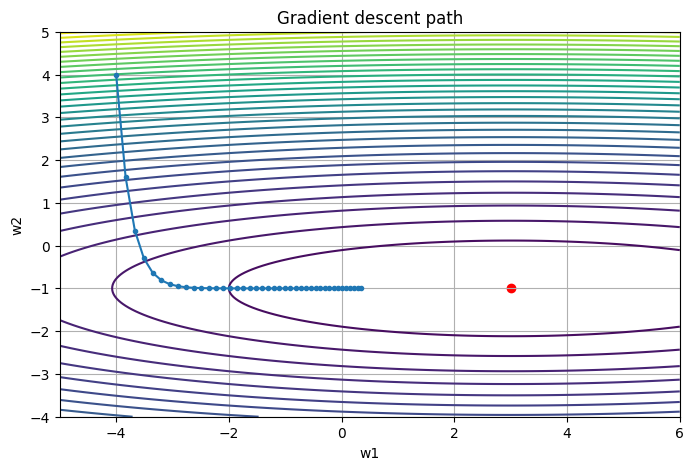

In [5]:
def run_gd(lr, steps=35, start=np.array([-4.0,4.0])):
    w = start.astype(float).copy()
    path = [w.copy()]
    losses = [loss_fn(w)]
    for _ in range(steps):
        w = w - lr * grad_fn(w)
        path.append(w.copy())
        losses.append(loss_fn(w))
    return np.array(path), np.array(losses)

path, losses = run_gd(0.12, 40)
plt.contour(X, Y, Z, levels=35)
plt.plot(path[:,0], path[:,1], 'o-', markersize=3)
plt.scatter([3], [-1], c='red')
plt.title('Gradient descent path')
plt.xlabel('w1'); plt.ylabel('w2');


## Step 3: Batch GD, SGD, and Mini-Batch GD

The optimizer needs a gradient. The question is: **gradient from how much data?**

| Method | Data used for one update | Behavior |
|---|---|---|
| Batch Gradient Descent | all training examples | stable but slow for large data |
| Stochastic Gradient Descent | one example | fast but noisy |
| Mini-Batch Gradient Descent | small batch | standard deep-learning choice |

**Why mini-batch is standard:** it uses vectorized hardware efficiently and gives a gradient estimate that is less noisy than one example but cheaper than the full dataset.


In [6]:
# Synthetic linear regression: y = 2x + 1 + noise
n = 120
x_data = rng.normal(size=n)
y_data = 2*x_data + 1 + rng.normal(scale=0.35, size=n)

def mse_grad_for_batch(w, b, xb, yb):
    pred = w*xb + b
    err = pred - yb
    dw = 2*np.mean(err*xb)
    db = 2*np.mean(err)
    return np.array([dw, db])

w0, b0 = -1.0, 0.0
full_grad = mse_grad_for_batch(w0, b0, x_data, y_data)
one_grad = mse_grad_for_batch(w0, b0, x_data[:1], y_data[:1])
batch_grad = mse_grad_for_batch(w0, b0, x_data[:16], y_data[:16])
display(pd.DataFrame({
    'method':['one-example SGD','mini-batch size 16','full batch'],
    'dw':[one_grad[0], batch_grad[0], full_grad[0]],
    'db':[one_grad[1], batch_grad[1], full_grad[1]]
}))


,method,dw,db
0,one-example SGD,-0.948235,-3.111854
1,mini-batch size 16,-4.551569,-1.523402
2,full batch,-3.498122,-1.614057


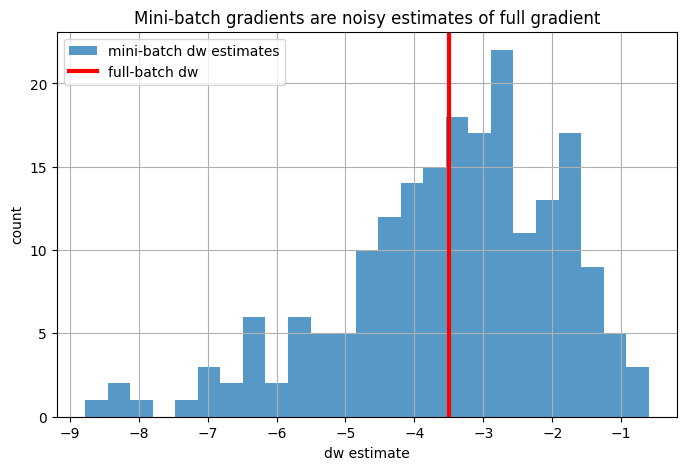

In [7]:
grads = []
for _ in range(200):
    idx = rng.choice(n, size=8, replace=False)
    grads.append(mse_grad_for_batch(w0, b0, x_data[idx], y_data[idx])[0])
plt.hist(grads, bins=25, alpha=0.75, label='mini-batch dw estimates')
plt.axvline(full_grad[0], color='red', linewidth=3, label='full-batch dw')
plt.title('Mini-batch gradients are noisy estimates of full gradient')
plt.xlabel('dw estimate'); plt.ylabel('count'); plt.legend();


## Step 4: Learning Rate Behavior

The learning rate controls step size. It is usually the first hyperparameter to check when training is bad.

* **Too small:** loss decreases very slowly.
* **Useful range:** loss decreases steadily.
* **Too large:** loss oscillates, diverges, or becomes NaN.

The same optimizer can look good or terrible depending on the learning rate.


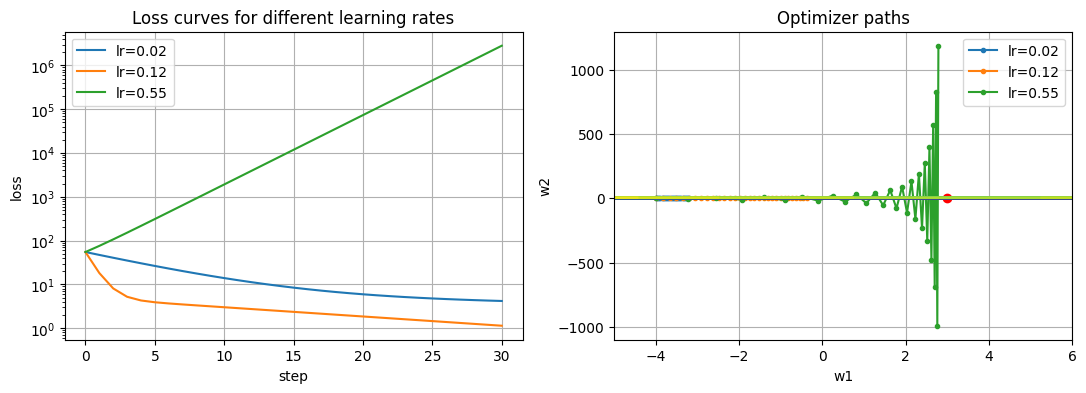

In [8]:
lrs = [0.02, 0.12, 0.55]
fig, axes = plt.subplots(1, 2, figsize=(13,4))
for lr in lrs:
    path, losses = run_gd(lr, 30)
    axes[0].plot(losses, label=f'lr={lr}')
    axes[1].plot(path[:,0], path[:,1], 'o-', markersize=3, label=f'lr={lr}')
axes[0].set_title('Loss curves for different learning rates')
axes[0].set_xlabel('step'); axes[0].set_ylabel('loss'); axes[0].set_yscale('log'); axes[0].legend()
axes[1].contour(X, Y, Z, levels=35)
axes[1].scatter([3],[-1],c='red')
axes[1].set_title('Optimizer paths')
axes[1].set_xlabel('w1'); axes[1].set_ylabel('w2'); axes[1].legend();


**Output meaning:** small learning rate is safe but slow. A useful learning rate moves quickly toward the minimum. A large learning rate can bounce across the steep direction or diverge.

**Common mistake:** switching optimizers before checking whether the learning rate is simply wrong.


## Step 5: Momentum

**Problem it solves:** plain gradient descent can zig-zag in steep valleys. Momentum adds a velocity that accumulates consistent directions and damps oscillation.

Classical momentum:

$$v_t=\beta v_{t-1}+g_t$$
$$w_t=w_{t-1}-\eta v_t$$

where $\beta$ is usually around 0.9.

**Intuition:** if gradients keep pointing in a similar direction, momentum builds speed. If gradients alternate direction, momentum cancels some oscillation.


,step,g_w1,g_w2,v_w1,v_w2,w1,w2,loss
0,1,-1.400000,20.000000,-1.400000,20.000000,-3.888000,2.400000,27.864454
1,2,-1.377600,13.600000,-2.567600,30.600000,-3.682592,-0.048000,6.278312
2,3,-1.336518,3.808000,-3.518978,29.818000,-3.401074,-2.433440,8.206875
3,4,-1.280215,-5.733760,-4.271346,19.611540,-3.059366,-4.002363,21.699961
4,5,-1.211873,-12.009453,-4.842518,4.660356,-2.671965,-4.375192,26.000956
5,6,-1.134393,-13.500767,-5.250533,-9.539464,-2.251922,-3.612035,16.403718


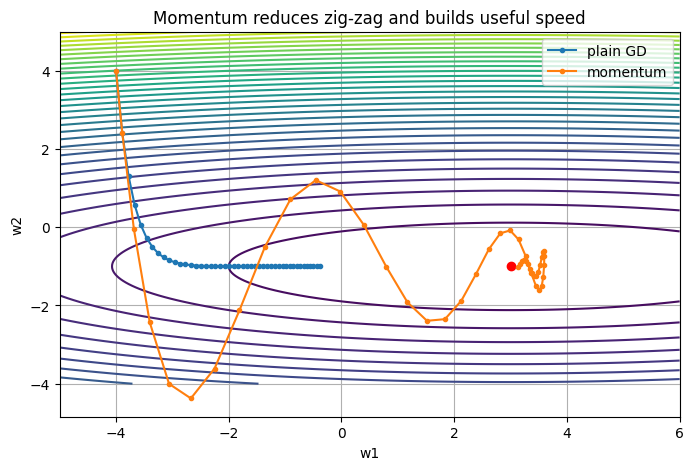

In [9]:
def run_momentum(lr=0.08, beta=0.9, steps=45, start=np.array([-4.0,4.0])):
    w = start.astype(float).copy()
    v = np.zeros_like(w)
    path, losses = [w.copy()], [loss_fn(w)]
    table = []
    for t in range(steps):
        g = grad_fn(w)
        v = beta*v + g
        w = w - lr*v
        path.append(w.copy()); losses.append(loss_fn(w))
        if t < 6:
            table.append([t+1, g[0], g[1], v[0], v[1], w[0], w[1], loss_fn(w)])
    return np.array(path), np.array(losses), pd.DataFrame(table, columns=['step','g_w1','g_w2','v_w1','v_w2','w1','w2','loss'])

gd_path, gd_losses = run_gd(0.08, 45)
mom_path, mom_losses, mom_table = run_momentum(0.08, 0.85, 45)
display(mom_table)
plt.contour(X, Y, Z, levels=35)
plt.plot(gd_path[:,0], gd_path[:,1], 'o-', markersize=3, label='plain GD')
plt.plot(mom_path[:,0], mom_path[:,1], 'o-', markersize=3, label='momentum')
plt.scatter([3],[-1],c='red')
plt.title('Momentum reduces zig-zag and builds useful speed')
plt.xlabel('w1'); plt.ylabel('w2'); plt.legend();


## Step 6: Nesterov Momentum

Nesterov momentum changes **where the gradient is measured**.

Classical momentum:

1. read gradient at current point;
2. update velocity;
3. move.

Nesterov:

1. look ahead using current velocity;
2. read gradient at the look-ahead point;
3. correct the update before moving.

This can reduce overshooting because the gradient is evaluated closer to where the velocity is already taking the parameters.


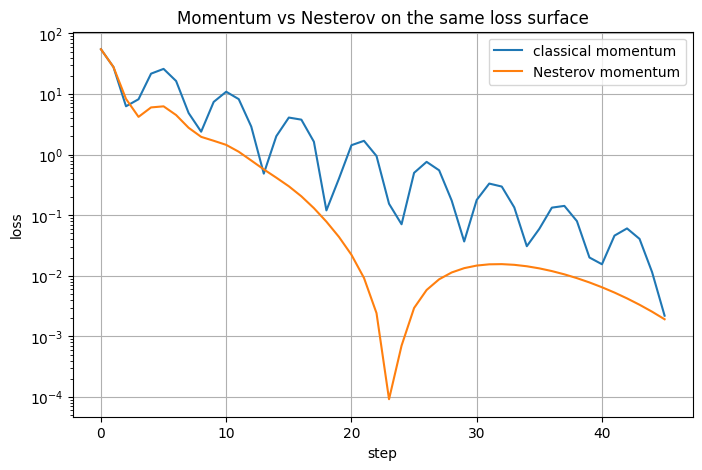

In [10]:
def run_nesterov(lr=0.08, beta=0.9, steps=45, start=np.array([-4.0,4.0])):
    w = start.astype(float).copy()
    v = np.zeros_like(w)
    path, losses = [w.copy()], [loss_fn(w)]
    for _ in range(steps):
        lookahead = w - lr*beta*v
        g = grad_fn(lookahead)
        v = beta*v + g
        w = w - lr*v
        path.append(w.copy()); losses.append(loss_fn(w))
    return np.array(path), np.array(losses)

nest_path, nest_losses = run_nesterov(0.08, 0.85, 45)
plt.plot(mom_losses, label='classical momentum')
plt.plot(nest_losses, label='Nesterov momentum')
plt.yscale('log')
plt.title('Momentum vs Nesterov on the same loss surface')
plt.xlabel('step'); plt.ylabel('loss'); plt.legend();


## Step 7: AdaGrad

**Problem it solves:** different parameters may need different step sizes. AdaGrad gives each parameter its own effective learning rate by accumulating squared gradients.

$$s_t=s_{t-1}+g_t^2$$
$$w_t=w_{t-1}-\eta\frac{g_t}{\sqrt{s_t}+\epsilon}$$

If a parameter has received many large gradients, its future step becomes smaller. This can help sparse features, such as rare words in text.

**Main issue:** $s_t$ only grows, so the effective learning rate can become too small during long training.


In [11]:
grads = np.array([
    [4.0, 0.2],
    [3.0, 0.1],
    [2.0, 0.1],
    [1.0, 0.1],
])
eta = 1.0
s = np.zeros(2)
rows = []
for t,g in enumerate(grads,1):
    s += g**2
    effective_lr = eta/(np.sqrt(s)+1e-8)
    update = effective_lr*g
    rows.append([t, g[0], g[1], s[0], s[1], effective_lr[0], effective_lr[1], update[0], update[1]])
display(pd.DataFrame(rows, columns=['step','g1','g2','s1','s2','eff_lr1','eff_lr2','update1','update2']))


,step,g1,g2,s1,s2,eff_lr1,eff_lr2,update1,update2
0,1,4.0,0.2,16.0,0.04,0.250000,5.000000,1.000000,1.000000
1,2,3.0,0.1,25.0,0.05,0.200000,4.472136,0.600000,0.447214
2,3,2.0,0.1,29.0,0.06,0.185695,4.082483,0.371391,0.408248
3,4,1.0,0.1,30.0,0.07,0.182574,3.779645,0.182574,0.377964


**Output meaning:** the coordinate with consistently large gradients gets its effective learning rate reduced quickly. The small-gradient coordinate keeps a larger effective learning rate.


## Step 8: RMSProp

RMSProp keeps AdaGrad's per-parameter scaling idea but replaces the forever-growing sum with a moving average:

$$s_t=\rho s_{t-1}+(1-\rho)g_t^2$$
$$w_t=w_{t-1}-\eta\frac{g_t}{\sqrt{s_t}+\epsilon}$$

**Problem it solves:** AdaGrad can stop learning because accumulated squared gradients grow forever. RMSProp forgets old gradients gradually.


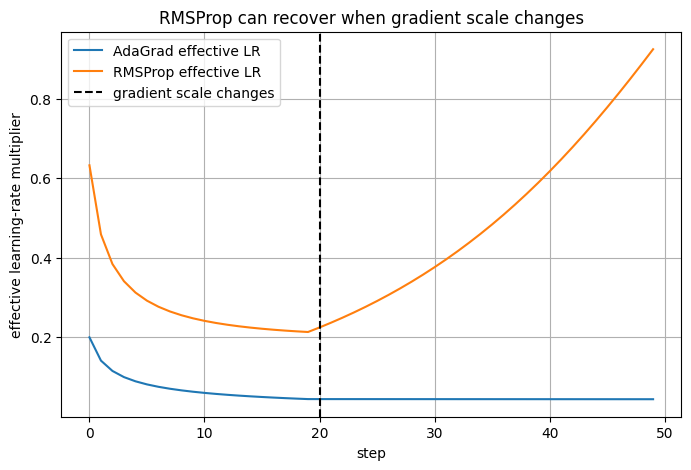

In [12]:
grad_sequence = np.r_[np.ones(20)*5, np.ones(30)*0.5]
adagrad_s = 0
rms_s = 0
rho = 0.9
ada_eff, rms_eff = [], []
for g in grad_sequence:
    adagrad_s += g*g
    rms_s = rho*rms_s + (1-rho)*g*g
    ada_eff.append(1/(np.sqrt(adagrad_s)+1e-8))
    rms_eff.append(1/(np.sqrt(rms_s)+1e-8))
plt.plot(ada_eff, label='AdaGrad effective LR')
plt.plot(rms_eff, label='RMSProp effective LR')
plt.axvline(20, color='black', linestyle='--', label='gradient scale changes')
plt.title('RMSProp can recover when gradient scale changes')
plt.xlabel('step'); plt.ylabel('effective learning-rate multiplier'); plt.legend();


## Step 9: Adam and AdamW

Adam combines two ideas:

* **Momentum:** moving average of gradients.
* **RMSProp:** moving average of squared gradients.

Adam equations:

$$m_t=\beta_1m_{t-1}+(1-\beta_1)g_t$$
$$v_t=\beta_2v_{t-1}+(1-\beta_2)g_t^2$$
$$\hat{m}_t=\frac{m_t}{1-\beta_1^t}, \quad \hat{v}_t=\frac{v_t}{1-\beta_2^t}$$
$$w_t=w_{t-1}-\eta\frac{\hat{m}_t}{\sqrt{\hat{v}_t}+\epsilon}$$

**AdamW:** decouples weight decay from Adam's adaptive gradient scaling. This is why AdamW is usually preferred over Adam with ordinary L2 regularization in modern transformer-style training.


In [13]:
g_seq = np.array([3.0, 2.0, 1.0, -0.5, -1.0])
beta1, beta2, eta = 0.9, 0.999, 0.1
m = 0.0; v = 0.0; w = 0.0
rows = []
for t,g in enumerate(g_seq,1):
    m = beta1*m + (1-beta1)*g
    v = beta2*v + (1-beta2)*g*g
    m_hat = m/(1-beta1**t)
    v_hat = v/(1-beta2**t)
    update = eta*m_hat/(np.sqrt(v_hat)+1e-8)
    w = w - update
    rows.append([t,g,m,v,m_hat,v_hat,update,w])
display(pd.DataFrame(rows, columns=['step','grad','m','v','m_hat','v_hat','update','w']))


,step,grad,m,v,m_hat,v_hat,update,w
0,1,3.0,0.30000,0.009000,3.000000,9.000000,0.100000,-0.100000
1,2,2.0,0.47000,0.012991,2.473684,6.498749,0.097035,-0.197035
2,3,1.0,0.52300,0.013978,1.929889,4.663999,0.089362,-0.286397
3,4,-0.5,0.42070,0.014214,1.223321,3.558842,0.064846,-0.351244
4,5,-1.0,0.27863,0.015200,0.680399,3.046049,0.038985,-0.390228


**Output meaning:** early Adam values use bias correction because moving averages start at zero. Adam's update is smoothed by $m$ and scaled by $v$.

**Common mistake:** thinking Adam always generalizes better. Adam/AdamW often trains fast, but SGD with momentum can still be strong in some vision settings.


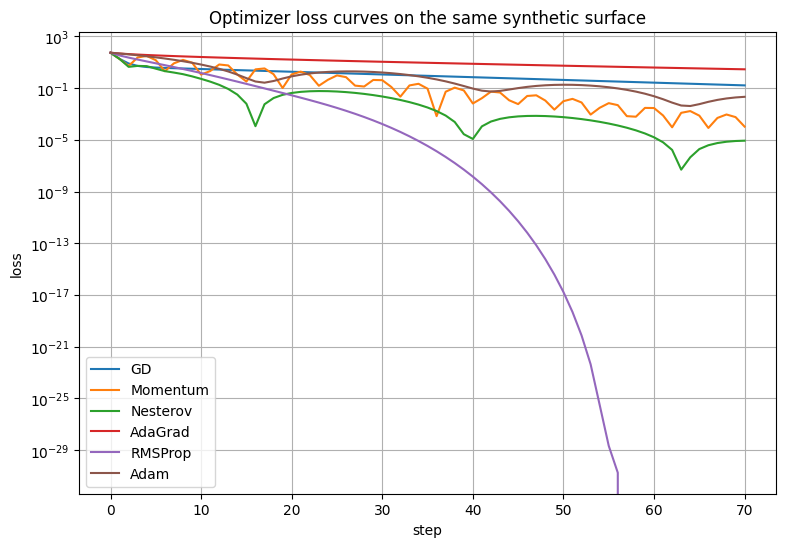

In [14]:
optimizers = ['GD','Momentum','Nesterov','AdaGrad','RMSProp','Adam']

def run_optimizer(name, lr=0.15, steps=60):
    w = np.array([-4.0, 4.0], dtype=float)
    v = np.zeros(2); s = np.zeros(2); m = np.zeros(2)
    path = [w.copy()]; losses = [loss_fn(w)]
    for t in range(1, steps+1):
        if name == 'Nesterov':
            g = grad_fn(w - lr*0.85*v)
        else:
            g = grad_fn(w)
        if name == 'GD':
            step = lr*g
        elif name == 'Momentum':
            v = 0.85*v + g; step = lr*v
        elif name == 'Nesterov':
            v = 0.85*v + g; step = lr*v
        elif name == 'AdaGrad':
            s += g*g; step = lr*g/(np.sqrt(s)+1e-8)
        elif name == 'RMSProp':
            s = 0.9*s + 0.1*g*g; step = lr*g/(np.sqrt(s)+1e-8)
        elif name == 'Adam':
            m = 0.9*m + 0.1*g; s = 0.999*s + 0.001*g*g
            mh = m/(1-0.9**t); sh = s/(1-0.999**t)
            step = lr*mh/(np.sqrt(sh)+1e-8)
        w = w - step
        path.append(w.copy()); losses.append(loss_fn(w))
    return np.array(path), np.array(losses)

plt.figure(figsize=(9,6))
for name in optimizers:
    _, los = run_optimizer(name, lr=0.12 if name in ['GD','Momentum','Nesterov'] else 0.35, steps=70)
    plt.plot(los, label=name)
plt.yscale('log')
plt.title('Optimizer loss curves on the same synthetic surface')
plt.xlabel('step'); plt.ylabel('loss'); plt.legend();


## Step 10: Learning-Rate Schedules

A schedule changes the learning rate over time.

**Why not keep LR constant?**

Early training often benefits from larger steps. Later training often needs smaller steps to settle. Schedules control this.

Common schedules:

* **Step decay:** drop LR at fixed milestones.
* **Exponential decay:** multiply LR by a decay factor continuously.
* **Cosine decay:** smoothly decay to a low value.
* **Cyclic LR:** repeatedly increase and decrease LR.
* **OneCycle:** increase then decrease, often with momentum changes.
* **ReduceLROnPlateau:** lower LR when validation stops improving.


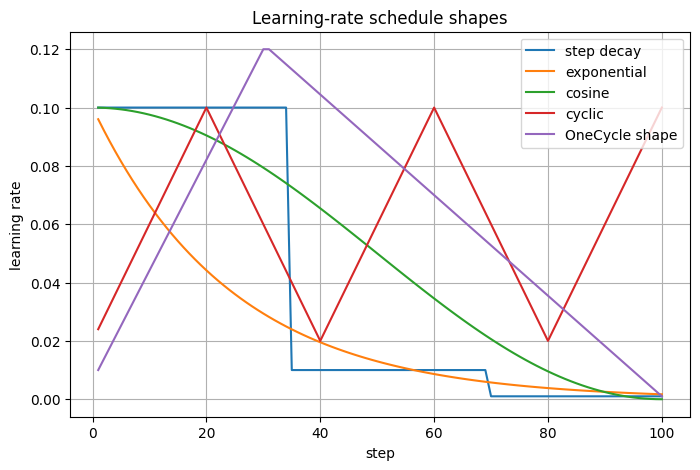

In [15]:
steps = np.arange(1, 101)
base = 0.1
step_decay = base * (0.1 ** (steps // 35))
exp_decay = base * (0.96 ** steps)
cos_decay = base * 0.5 * (1 + np.cos(np.pi * steps / steps.max()))
cyclic = 0.02 + 0.08 * (1 - np.abs((steps % 40)/20 - 1))
onecycle = np.r_[np.linspace(0.01,0.12,30), np.linspace(0.12,0.001,70)]
plt.plot(steps, step_decay, label='step decay')
plt.plot(steps, exp_decay, label='exponential')
plt.plot(steps, cos_decay, label='cosine')
plt.plot(steps, cyclic, label='cyclic')
plt.plot(steps, onecycle, label='OneCycle shape')
plt.title('Learning-rate schedule shapes')
plt.xlabel('step'); plt.ylabel('learning rate'); plt.legend();


**Common mistake:** copying a schedule without matching total training steps. A cosine schedule for 100 epochs behaves differently if training actually stops at 10 epochs.


## Step 11: Warmup

Warmup gradually increases LR at the start of training.

**Problem it solves:** early optimizer statistics and activations can be unstable. A large LR at step 1 can damage training before the model has stable gradients.

Warmup is especially common in:

* transformers;
* large-batch training;
* fine-tuning;
* AdamW training recipes.


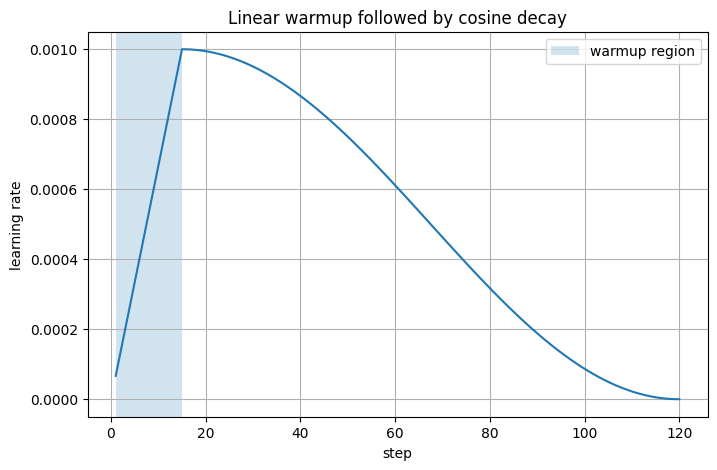

In [16]:
total = 120
warmup = 15
max_lr = 0.001
steps = np.arange(1,total+1)
warm = np.minimum(steps/warmup, 1.0) * max_lr
cos = max_lr * 0.5 * (1 + np.cos(np.pi * np.maximum(steps-warmup,0)/(total-warmup)))
warm_cos = np.where(steps <= warmup, warm, cos)
plt.plot(steps, warm_cos)
plt.axvspan(1, warmup, alpha=0.2, label='warmup region')
plt.title('Linear warmup followed by cosine decay')
plt.xlabel('step'); plt.ylabel('learning rate'); plt.legend();


## Step 12: Gradient Clipping

Gradient clipping limits gradients before the optimizer update.

**Problem it solves:** exploding gradients. If a gradient is huge, one update can throw parameters into a bad region and make loss become NaN.

Two common forms:

### Norm clipping

If the gradient vector norm is larger than threshold $c$:

$$g_{clipped}=g\frac{c}{\|g\|}$$

This keeps direction but limits size.

### Value clipping

Each gradient component is capped to a range, such as [-1, 1].

This is simpler but can change direction more than norm clipping.


,gradient,g1,g2,norm
0,original,30.0,40.0,50.000000
1,norm clipped,3.0,4.0,5.000000
2,value clipped,5.0,5.0,7.071068


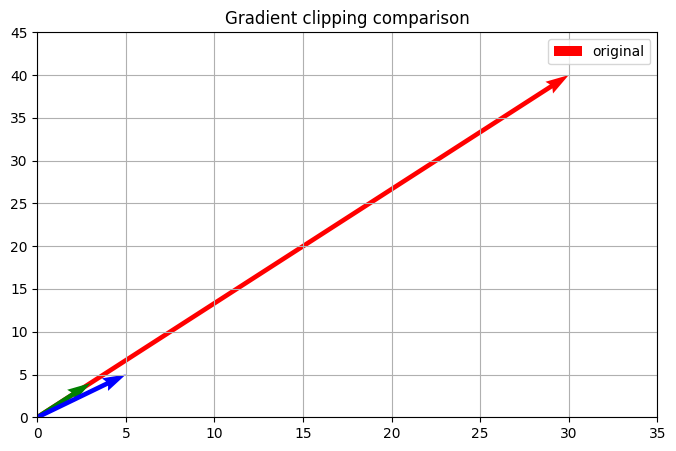

In [17]:
g = np.array([30.0, 40.0])
threshold = 5.0
norm = np.linalg.norm(g)
g_norm_clipped = g * min(1, threshold/norm)
g_value_clipped = np.clip(g, -threshold, threshold)
display(pd.DataFrame({
    'gradient':['original','norm clipped','value clipped'],
    'g1':[g[0], g_norm_clipped[0], g_value_clipped[0]],
    'g2':[g[1], g_norm_clipped[1], g_value_clipped[1]],
    'norm':[np.linalg.norm(g), np.linalg.norm(g_norm_clipped), np.linalg.norm(g_value_clipped)]
}))

plt.quiver([0,0,0],[0,0,0],
           [g[0],g_norm_clipped[0],g_value_clipped[0]],
           [g[1],g_norm_clipped[1],g_value_clipped[1]],
           angles='xy', scale_units='xy', scale=1,
           color=['red','green','blue'])
plt.xlim(0,35); plt.ylim(0,45)
plt.title('Gradient clipping comparison')
plt.legend(['original','norm clipped','value clipped']);


**When to use clipping:** RNNs, RL, sequence models, mixed precision, or any run where gradient norms spike.

**Important:** clipping is not a cure for every training problem. If gradients constantly explode, also check learning rate, initialization, loss scale, normalization, data outliers, and bugged labels.


## Step 13: Optimizer Selection Workflow

Use this practical order:

1. Start with a simple baseline optimizer.
2. Find a reasonable learning-rate range.
3. Watch loss curve and gradient norm.
4. Use AdamW for transformers/fine-tuning or when quick stable training is needed.
5. Use SGD + momentum as a strong vision baseline.
6. Add schedule and warmup when training is long or unstable early.
7. Add clipping only when gradient spikes or exploding gradients are visible.
8. Compare validation performance, not just training speed.


### Quick Decision Table

| Situation | Good first choice | Why |
|---|---|---|
| Teaching basic optimization | plain GD on 2D surface | easiest to visualize |
| CNN image classifier | SGD + momentum or AdamW | both are common baselines |
| Transformer fine-tuning | AdamW + warmup + decay | standard stable recipe |
| Sparse features / rare tokens | AdaGrad-style intuition | rare parameters benefit from adaptive scaling |
| RNN or RL instability | gradient clipping + careful LR | reduces destructive gradient spikes |
| Loss decreases too slowly | LR range check, schedule, momentum | optimizer may be under-stepping |
| Loss explodes | lower LR, check data/loss, clipping | step size or gradients may be too large |


## Step 14: Loss Geometry Problems Optimizers Must Handle

Before choosing an optimizer, understand the **shape problem** the optimizer is trying to handle.

Neural-network optimization is hard because the loss surface can contain:

* **ravines:** one direction is steep, another is flat;
* **plateaus:** gradients are tiny, so learning becomes slow;
* **saddle points:** gradient can be near zero but the point is not a true minimum;
* **sharp minima:** loss rises quickly around the solution;
* **flat minima:** loss changes slowly around the solution and often generalizes better.

Optimizers are not magic. They are different strategies for moving through these shapes using local gradient information.


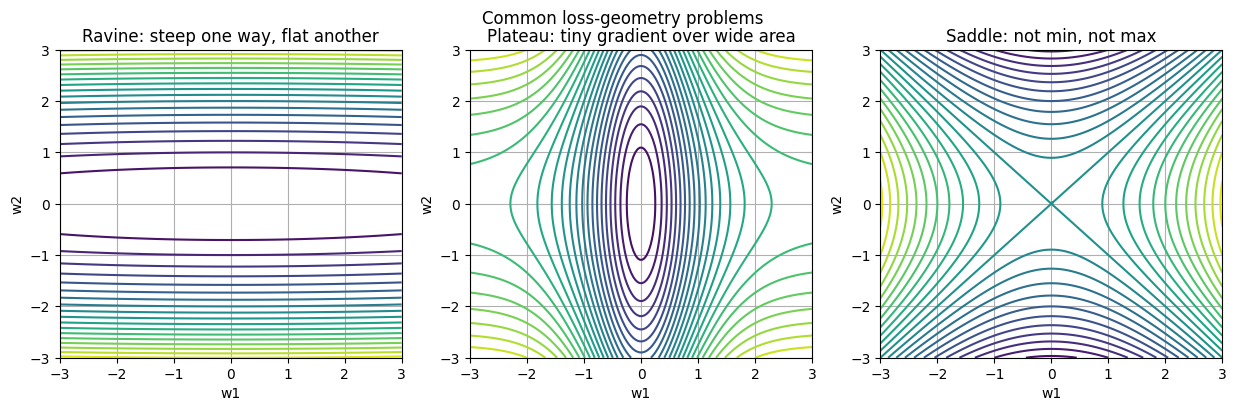

In [18]:
fig, axes = plt.subplots(1, 3, figsize=(15,4))

# Ravine
xr = np.linspace(-3,3,160); yr = np.linspace(-3,3,160)
XR,YR=np.meshgrid(xr,yr)
ravine = 0.05*XR**2 + 3*YR**2
axes[0].contour(XR,YR,ravine,levels=25)
axes[0].set_title('Ravine: steep one way, flat another')

# Plateau
plateau = np.tanh(XR)**2 + 0.05*YR**2
axes[1].contour(XR,YR,plateau,levels=25)
axes[1].set_title('Plateau: tiny gradient over wide area')

# Saddle
saddle = XR**2 - YR**2
axes[2].contour(XR,YR,saddle,levels=25)
axes[2].set_title('Saddle: not min, not max')

for ax in axes:
    ax.set_xlabel('w1'); ax.set_ylabel('w2')
plt.suptitle('Common loss-geometry problems');


**How to read the visual:** in a ravine, plain gradient descent zig-zags. On a plateau, any optimizer may look slow because gradients are small. Near a saddle, the gradient may be small even though better directions exist. Momentum and adaptive methods help with some of these, but no optimizer solves every geometry problem perfectly.


## Step 15: Batch Size, Gradient Noise, and Generalization

Batch size changes the gradient estimate.

* **Small batch:** noisy gradient, more updates per epoch, sometimes better generalization, less memory.
* **Large batch:** smoother gradient, better hardware use, fewer updates per epoch, may need LR scaling/warmup.
* **Gradient accumulation:** simulates a larger batch by accumulating gradients over several smaller mini-batches before stepping.

If dataset size is 10,000 and batch size is 100:

$$iterations\ per\ epoch = 10000 / 100 = 100$$

If batch size becomes 500:

$$iterations\ per\ epoch = 10000 / 500 = 20$$

So changing batch size changes both gradient noise and number of optimizer updates.


,batch_size,iterations_per_epoch,relative_gradient_noise_approx
0,16,625,0.2500
1,32,313,0.1768
2,64,157,0.1250
3,128,79,0.0884
4,256,40,0.0625
5,512,20,0.0442
6,1024,10,0.0312


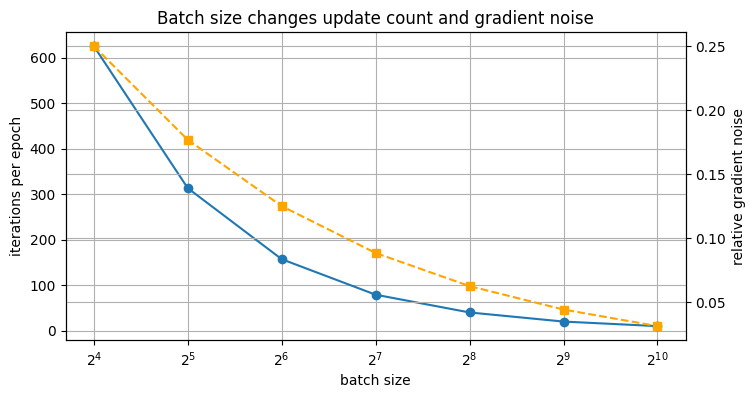

In [19]:
dataset_size = 10_000
batch_sizes = np.array([16, 32, 64, 128, 256, 512, 1024])
iters = np.ceil(dataset_size / batch_sizes).astype(int)
relative_noise = 1/np.sqrt(batch_sizes)
display(pd.DataFrame({
    'batch_size': batch_sizes,
    'iterations_per_epoch': iters,
    'relative_gradient_noise_approx': np.round(relative_noise, 4)
}))

fig, ax1 = plt.subplots(figsize=(8,4))
ax1.plot(batch_sizes, iters, 'o-', label='iterations per epoch')
ax1.set_xscale('log', base=2)
ax1.set_xlabel('batch size')
ax1.set_ylabel('iterations per epoch')
ax2 = ax1.twinx()
ax2.plot(batch_sizes, relative_noise, 's--', color='orange', label='gradient noise approx')
ax2.set_ylabel('relative gradient noise')
plt.title('Batch size changes update count and gradient noise');


**Common mistake:** increasing batch size without changing learning rate or warmup. Large batches often need a different LR strategy because the update count and gradient noise change.


## Step 16: Optimizer State Memory

Optimizers store extra tensors. This matters for large models.

Assume a model has one parameter tensor $w$.

| Optimizer | Extra state per parameter | Meaning |
|---|---:|---|
| SGD | 0 | only weights and gradients |
| SGD + Momentum | 1 | velocity |
| RMSProp | 1 | moving average of squared gradients |
| Adam / AdamW | 2 | first moment and second moment |
| AMSGrad | 3 | first moment, second moment, max second moment |

For a billion-parameter model, optimizer state can be larger than the model weights themselves.


In [20]:
params = np.array([1e6, 1e8, 1e9])
bytes_per_float = 4
states = {
    'SGD': 0,
    'Momentum/RMSProp': 1,
    'Adam/AdamW': 2,
    'AMSGrad': 3,
}
rows=[]
for pcount in params:
    for opt, extra in states.items():
        weight_mem = pcount * bytes_per_float / 1e9
        state_mem = pcount * extra * bytes_per_float / 1e9
        rows.append([int(pcount), opt, round(weight_mem,2), round(state_mem,2), round(weight_mem+state_mem,2)])
display(pd.DataFrame(rows, columns=['parameters','optimizer','weights_GB_fp32','optimizer_state_GB','weights_plus_state_GB']))


,parameters,optimizer,weights_GB_fp32,optimizer_state_GB,weights_plus_state_GB
0,1000000,SGD,0.0,0.00,0.00
1,1000000,Momentum/RMSProp,0.0,0.00,0.01
2,1000000,Adam/AdamW,0.0,0.01,0.01
3,1000000,AMSGrad,0.0,0.01,0.02
4,100000000,SGD,0.4,0.00,0.40
5,100000000,Momentum/RMSProp,0.4,0.40,0.80
6,100000000,Adam/AdamW,0.4,0.80,1.20
7,100000000,AMSGrad,0.4,1.20,1.60
8,1000000000,SGD,4.0,0.00,4.00
9,1000000000,Momentum/RMSProp,4.0,4.00,8.00


**Why this matters:** AdamW may train very well, but it stores more state than SGD. In large models, memory can decide which optimizer, precision, batch size, or distributed strategy is possible.


## Step 17: L2 Regularization vs AdamW Weight Decay

This is a common confusion.

### L2 regularization

Adds a penalty to the loss:

$$L_{total}=L_{data}+\lambda\|w\|^2$$

The gradient becomes:

$$g_{total}=g_{data}+2\lambda w$$

### Decoupled weight decay in AdamW

AdamW applies weight shrinkage separately from the adaptive gradient update:

$$w \leftarrow w - \eta \cdot update - \eta\lambda w$$

**Why it matters:** In Adam, adding L2 to the gradient means the penalty is passed through Adam's adaptive scaling. AdamW keeps weight decay as a cleaner direct shrinkage.


In [21]:
w = 10.0
grad_data = 0.5
lr = 0.1
wd = 0.1

# SGD with L2-style gradient penalty, using derivative lambda*w for simple illustration
grad_l2 = grad_data + wd*w
w_l2 = w - lr*grad_l2

# AdamW-style decoupled decay simplified: gradient step plus separate decay
w_adamw_style = w - lr*grad_data - lr*wd*w

display(pd.DataFrame({
    'method':['gradient with L2 penalty','decoupled weight decay'],
    'starting_w':[w,w],
    'data_gradient':[grad_data,grad_data],
    'weight_decay_strength':[wd,wd],
    'new_w':[w_l2,w_adamw_style]
}))


,method,starting_w,data_gradient,weight_decay_strength,new_w
0,gradient with L2 penalty,10.0,0.5,0.1,9.85
1,decoupled weight decay,10.0,0.5,0.1,9.85


In simple SGD, these can look similar. In Adam-style adaptive optimizers, they behave differently because Adam rescales gradients per parameter. That is the practical reason AdamW is preferred in many modern recipes.


## Step 18: Advanced Optimizer Variants

These are not needed before understanding SGD, Momentum, RMSProp, Adam, and AdamW. But students should know why they exist.

| Optimizer | Main idea | Where it appears |
|---|---|---|
| AdaDelta | RMSProp-like method designed to reduce manual LR dependence | older deep-learning recipes |
| Adamax | Adam variant using infinity norm | some sparse/noisy settings |
| Nadam | Adam plus Nesterov-style momentum | alternative Adam variant |
| AMSGrad | Adam variant that keeps maximum second moment | convergence-focused Adam fix |
| LARS | layer-wise adaptive rate scaling | very large-batch CNN training |
| LAMB | Adam-like layer-wise scaling | large-batch transformer/BERT-style training |
| Lion | sign-based optimizer using momentum-like updates | newer large-model experiments |
| SAM | sharpness-aware minimization | improves flatness/generalization in some settings |

The important lesson: advanced optimizers usually solve a specific training issue. They should be introduced after diagnosing the issue, not chosen because the name is advanced.


## Step 19: Learning-Rate Finder

An LR finder tries a range of learning rates from very small to large and records loss. The goal is not to train the model fully. The goal is to find a range where loss starts decreasing before it becomes unstable.

A typical interpretation:

* LR too small: loss barely changes.
* LR useful: loss drops quickly.
* LR too large: loss spikes or becomes noisy/divergent.

Choose a learning rate below the unstable region, not at the largest value that ever worked.


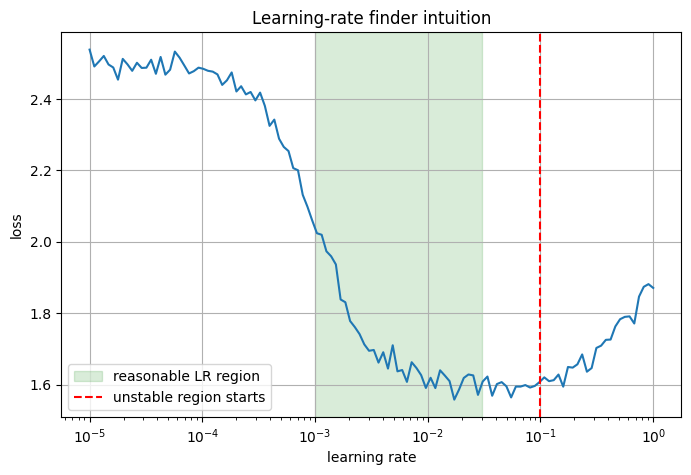

In [22]:
lrs = np.logspace(-5, 0, 120)
# Simulated LR finder curve: flat -> improving -> unstable
sim_loss = 2.5 - 0.9/(1+np.exp(-(np.log10(lrs)+3)*4)) + 0.2*np.maximum(0, np.log10(lrs)+1.2)**2
sim_loss += rng.normal(scale=0.02, size=len(lrs))
plt.plot(lrs, sim_loss)
plt.xscale('log')
plt.axvspan(1e-3, 3e-2, color='green', alpha=0.15, label='reasonable LR region')
plt.axvline(1e-1, color='red', linestyle='--', label='unstable region starts')
plt.title('Learning-rate finder intuition')
plt.xlabel('learning rate'); plt.ylabel('loss'); plt.legend();


**Common mistake:** selecting the learning rate at the lowest point of the LR-finder curve. By then the model may already be near instability. Choose a safer value earlier in the steep downward region.


## Step 20: Parameter Groups and Fine-Tuning

In real workflows, different parameter groups may use different learning rates or weight decay.

Examples:

* pretrained backbone: small LR;
* newly initialized classifier head: larger LR;
* bias and normalization parameters: often no weight decay;
* embeddings: sometimes separate LR or decay settings.

This matters in transfer learning and transformer fine-tuning. One global LR may either damage pretrained layers or train the new head too slowly.


In [23]:
groups = pd.DataFrame({
    'parameter_group':['pretrained backbone','new classifier head','bias terms','LayerNorm / BatchNorm parameters','embedding table'],
    'example_lr':[1e-5, 1e-3, 1e-3, 1e-3, 5e-5],
    'weight_decay':['yes, small','yes','usually no','usually no','depends'],
    'reason':['preserve learned features','learn new task quickly','bias shrinkage often unhelpful','normalization scale/shift should not be penalized','embeddings may need careful tuning']
})
display(groups)


,parameter_group,example_lr,weight_decay,reason
0,pretrained backbone,0.00001,"yes, small",preserve learned features
1,new classifier head,0.00100,yes,learn new task quickly
2,bias terms,0.00100,usually no,bias shrinkage often unhelpful
3,LayerNorm / BatchNorm parameters,0.00100,usually no,normalization scale/shift should not be penalized
4,embedding table,0.00005,depends,embeddings may need careful tuning


## Step 21: Mixed Precision and Loss Scaling

Mixed precision uses lower precision such as float16 or bfloat16 to speed training and reduce memory.

**Problem:** float16 can underflow small gradients to zero.

**Loss scaling idea:**

1. multiply the loss by a scale value;
2. backpropagate larger gradients;
3. unscale gradients before optimizer step;
4. skip or adjust if overflow is detected.

This is why optimizer stability is not only about math formulas. Numeric representation also matters.


In [24]:
small_grads = np.array([1e-8, 5e-8, 1e-7, 1e-6], dtype=np.float32)
as_float16 = small_grads.astype(np.float16)
scale = 1024
scaled_then_float16 = (small_grads * scale).astype(np.float16)
unscaled_back = (scaled_then_float16.astype(np.float32) / scale)
display(pd.DataFrame({
    'original_grad': small_grads,
    'direct_float16': as_float16,
    'scaled_float16_then_unscaled': unscaled_back
}))


C:\Users\91832\Desktop\ML-Learning\.venv\lib\site-packages\pandas\io\formats\format.py:1458: RuntimeWarning: overflow encountered in cast
  has_large_values = (abs_vals > 1e6).any()


,original_grad,direct_float16,scaled_float16_then_unscaled
0,1.000000e-08,0.000000e+00,1.001172e-08
1,5.000000e-08,5.960464e-08,5.000038e-08
2,1.000000e-07,1.192093e-07,1.000008e-07
3,1.000000e-06,1.013279e-06,1.000240e-06


**Output meaning:** very small gradients may become zero in float16. Scaling can preserve more signal before the optimizer step.


## Step 22: Optimizer Debugging Checklist

When training is bad, do not randomly switch optimizers. Diagnose the pattern.

| Symptom | Likely causes | What to check first |
|---|---|---|
| loss is NaN | LR too high, exploding gradients, invalid loss, mixed precision overflow | lower LR, inspect inputs/labels, gradient norm, clipping |
| loss decreases very slowly | LR too low, bad initialization, frozen parameters | LR finder, gradients not zero, trainable parameters |
| train loss falls, validation worsens | overfitting, bad regularization, data leakage | validation split, augmentation, weight decay, early stopping |
| gradients are zero | saturation, detached graph, frozen layers, bad activation | gradient histograms, requires_grad, activation ranges |
| gradients explode | high LR, long sequence, bad initialization, outliers | gradient norm, clipping, normalization, data scale |
| Adam trains but SGD fails | LR/momentum not tuned, scaling issue | tune SGD LR, add momentum, check schedule |
| SGD generalizes better than Adam | common in some vision setups | compare validation, not just training speed |


### Final Practical Rule

For a beginner project:

1. Start with AdamW and a reasonable LR if you need stable quick training.
2. Try SGD + momentum for CNN vision baselines.
3. Always plot train and validation curves.
4. Track gradient norm when training is unstable.
5. Use warmup for transformers or large batches.
6. Use clipping only when gradient spikes are real.
7. Choose the optimizer based on evidence from curves and metrics.


## Step 23: From-Scratch Optimizer Masterclass

This section teaches optimizers in the style used by strong visual/video explanations: every optimizer is introduced because the previous method has a specific weakness.

The progression is:

1. **Gradient Descent:** follows steepest downhill direction.
2. **SGD / Mini-batch SGD:** uses noisy but faster gradient estimates.
3. **Momentum:** fixes zig-zagging by averaging gradient direction.
4. **AdaGrad:** gives each parameter its own learning rate using accumulated squared gradients.
5. **RMSProp:** fixes AdaGrad's shrinking-learning-rate problem by using a moving average.
6. **Adam:** combines Momentum's first-moment average with RMSProp's second-moment average.
7. **AdamW:** keeps Adam's adaptive update but applies weight decay separately.

The key idea from visual explanations is simple: optimizers behave differently because they store different **memory** from previous gradients.


### Optimizer Memory Table

| Optimizer | What it remembers | What problem it tries to solve |
|---|---|---|
| GD / SGD | nothing | simple downhill movement |
| Momentum | average gradient direction | zig-zagging and slow ravine movement |
| AdaGrad | sum of squared gradients | different coordinates need different step sizes |
| RMSProp | moving average of squared gradients | AdaGrad step sizes shrink too much |
| Adam | average gradient + average squared gradient | combine smoother direction with adaptive scaling |
| AdamW | Adam state + separate decay | regularize weights cleanly with adaptive optimizers |

This table should be understood before memorizing formulas.


### A Harder Visual Surface: Rosenbrock Valley

The Rosenbrock function is often used to visualize optimizer behavior:

$$
f(x,y)=(1-x)^2+100(y-x^2)^2
$$

It has a narrow curved valley. The minimum is at $(1,1)$, but the optimizer can bounce around or move slowly because the valley is curved and steep on the sides.


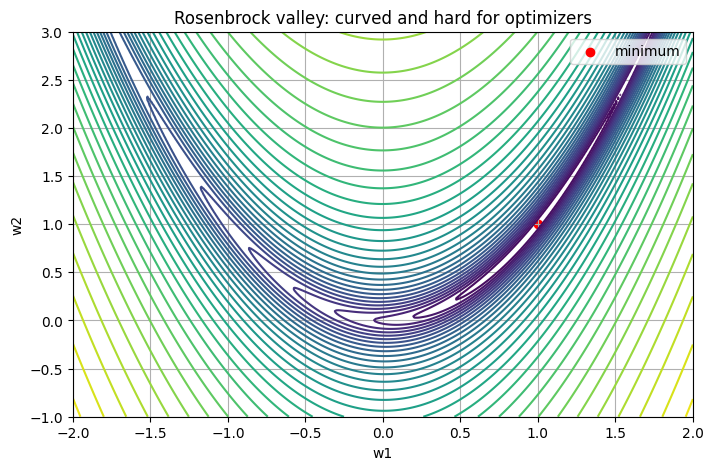

In [25]:
def rosenbrock(w):
    x, y = w[0], w[1]
    return (1-x)**2 + 100*(y-x*x)**2

def rosen_grad(w):
    x, y = w[0], w[1]
    dx = -2*(1-x) - 400*x*(y-x*x)
    dy = 200*(y-x*x)
    return np.array([dx, dy])

rx = np.linspace(-2, 2, 300)
ry = np.linspace(-1, 3, 300)
RX, RY = np.meshgrid(rx, ry)
RZ = (1-RX)**2 + 100*(RY-RX**2)**2
plt.contour(RX, RY, np.log1p(RZ), levels=35)
plt.scatter([1],[1],c='red',label='minimum')
plt.title('Rosenbrock valley: curved and hard for optimizers')
plt.xlabel('w1'); plt.ylabel('w2'); plt.legend();


### From-Scratch Optimizer Implementations

The following code implements the major optimizers directly. This is important because learners often call `optimizer.step()` without understanding what changes internally.

Each optimizer receives:

* current parameters `w`;
* current gradient `g`;
* a state dictionary storing memory such as velocity or squared-gradient averages.


In [26]:
def optimizer_step(name, w, g, state, lr=0.001, beta=0.9, beta1=0.9, beta2=0.999, rho=0.9, eps=1e-8, weight_decay=0.0):
    if name == 'SGD':
        step = lr * g
        w = w - step

    elif name == 'Momentum':
        v = state.get('v', np.zeros_like(w))
        v = beta * v + g
        w = w - lr * v
        state['v'] = v

    elif name == 'Nesterov':
        # In this simple lab, caller supplies gradient at lookahead externally when needed.
        v = state.get('v', np.zeros_like(w))
        v = beta * v + g
        w = w - lr * v
        state['v'] = v

    elif name == 'AdaGrad':
        s = state.get('s', np.zeros_like(w))
        s = s + g*g
        w = w - lr * g / (np.sqrt(s) + eps)
        state['s'] = s

    elif name == 'RMSProp':
        s = state.get('s', np.zeros_like(w))
        s = rho*s + (1-rho)*g*g
        w = w - lr * g / (np.sqrt(s) + eps)
        state['s'] = s

    elif name == 'Adam':
        t = state.get('t', 0) + 1
        m = state.get('m', np.zeros_like(w))
        v = state.get('v', np.zeros_like(w))
        m = beta1*m + (1-beta1)*g
        v = beta2*v + (1-beta2)*g*g
        m_hat = m / (1-beta1**t)
        v_hat = v / (1-beta2**t)
        w = w - lr * m_hat / (np.sqrt(v_hat) + eps)
        state.update({'m':m, 'v':v, 't':t})

    elif name == 'AdamW':
        t = state.get('t', 0) + 1
        m = state.get('m', np.zeros_like(w))
        v = state.get('v', np.zeros_like(w))
        m = beta1*m + (1-beta1)*g
        v = beta2*v + (1-beta2)*g*g
        m_hat = m / (1-beta1**t)
        v_hat = v / (1-beta2**t)
        adaptive_step = lr * m_hat / (np.sqrt(v_hat) + eps)
        decay_step = lr * weight_decay * w
        w = w - adaptive_step - decay_step
        state.update({'m':m, 'v':v, 't':t})

    return w, state


### Optimizer Race on the Same Rosenbrock Valley

A good visual comparison should keep the starting point and surface the same. Then the only difference is the optimizer update rule.


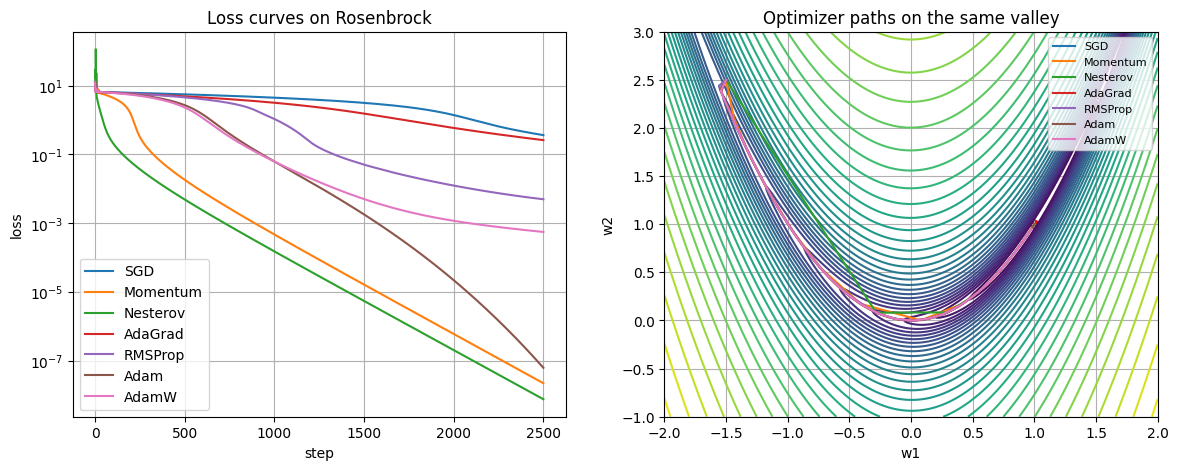

In [27]:
def run_optimizer_on_rosen(name, start=np.array([-1.5, 2.5]), steps=2500, lr=0.001):
    w = start.astype(float).copy()
    state = {}
    path = [w.copy()]
    losses = [rosenbrock(w)]
    for _ in range(steps):
        if name == 'Nesterov':
            v = state.get('v', np.zeros_like(w))
            lookahead = w - lr*0.9*v
            g = rosen_grad(lookahead)
        else:
            g = rosen_grad(w)
        w, state = optimizer_step(name, w, g, state, lr=lr, weight_decay=0.01)
        if np.any(~np.isfinite(w)):
            break
        path.append(w.copy())
        losses.append(rosenbrock(w))
    return np.array(path), np.array(losses)

settings = {
    'SGD': 0.0008,
    'Momentum': 0.0008,
    'Nesterov': 0.0008,
    'AdaGrad': 0.12,
    'RMSProp': 0.003,
    'Adam': 0.02,
    'AdamW': 0.02,
}
results = {}
for name, lr in settings.items():
    results[name] = run_optimizer_on_rosen(name, lr=lr)

fig, axes = plt.subplots(1, 2, figsize=(14,5))
for name, (path, losses) in results.items():
    axes[0].plot(losses, label=name)
axes[0].set_yscale('log')
axes[0].set_title('Loss curves on Rosenbrock')
axes[0].set_xlabel('step'); axes[0].set_ylabel('loss'); axes[0].legend()

axes[1].contour(RX, RY, np.log1p(RZ), levels=35)
for name, (path, _) in results.items():
    sampled = path[::max(1, len(path)//80)]
    axes[1].plot(sampled[:,0], sampled[:,1], label=name)
axes[1].scatter([1],[1],c='red')
axes[1].set_title('Optimizer paths on the same valley')
axes[1].set_xlabel('w1'); axes[1].set_ylabel('w2'); axes[1].legend(fontsize=8);


**How to interpret this visual:**

* SGD can be slow because it only follows the current gradient.
* Momentum smooths the path by remembering direction.
* AdaGrad can move quickly at first, then slow because accumulated squared gradients keep growing.
* RMSProp adapts step sizes without permanently shrinking them.
* Adam often moves quickly because it combines direction smoothing and adaptive scaling.
* AdamW behaves like Adam here, with extra separate weight shrinkage.

The exact winner depends on learning rate, surface, and task. The purpose is not to crown one optimizer; it is to see the behavior difference.


## Step 24: Manual RMSProp Calculation

RMSProp is often confusing because learners hear “root mean square” but do not see the numbers.

Assume one parameter has gradients:

$$g=[4, 2, 1]$$

Use:

$$s_t=0.9s_{t-1}+0.1g_t^2$$

and update multiplier:

$$\frac{g_t}{\sqrt{s_t}+\epsilon}$$

The table below shows why RMSProp reduces the effect of consistently large gradients.


In [28]:
grads = [4.0, 2.0, 1.0, 1.0, 0.5]
s = 0.0
rho = 0.9
rows = []
for t,g in enumerate(grads,1):
    s = rho*s + (1-rho)*g*g
    scaled_grad = g/(np.sqrt(s)+1e-8)
    rows.append([t,g,g*g,s,np.sqrt(s),scaled_grad])
display(pd.DataFrame(rows, columns=['step','gradient g','g^2','RMSProp s','sqrt(s)','scaled gradient g/sqrt(s)']))


,step,gradient g,g^2,RMSProp s,sqrt(s),scaled gradient g/sqrt(s)
0,1,4.0,16.00,1.60000,1.264911,3.162278
1,2,2.0,4.00,1.84000,1.356466,1.474420
2,3,1.0,1.00,1.75600,1.325142,0.754636
3,4,1.0,1.00,1.68040,1.296302,0.771425
4,5,0.5,0.25,1.53736,1.239903,0.403257


**What this table means:** RMSProp is not just “smaller learning rate.” It is a different effective learning rate for each parameter based on recent squared-gradient size.


## Step 25: Manual Adam Calculation

Adam has two memory tracks:

* $m_t$ = moving average of gradients, like momentum;
* $v_t$ = moving average of squared gradients, like RMSProp.

Bias correction matters because both $m$ and $v$ start at zero. Without correction, early steps are biased toward zero.


In [29]:
grads = [4.0, 2.0, 1.0]
beta1, beta2 = 0.9, 0.999
m = 0.0
v = 0.0
rows = []
for t,g in enumerate(grads,1):
    m = beta1*m + (1-beta1)*g
    v = beta2*v + (1-beta2)*g*g
    m_hat = m/(1-beta1**t)
    v_hat = v/(1-beta2**t)
    adam_direction = m_hat/(np.sqrt(v_hat)+1e-8)
    rows.append([t,g,m,v,m_hat,v_hat,adam_direction])
display(pd.DataFrame(rows, columns=['step','g','m raw','v raw','m_hat corrected','v_hat corrected','Adam scaled direction']))


,step,g,m raw,v raw,m_hat corrected,v_hat corrected,Adam scaled direction
0,1,4.0,0.400,0.016000,4.000000,16.000000,1.000000
1,2,2.0,0.560,0.019984,2.947368,9.996998,0.932180
2,3,1.0,0.604,0.020964,2.228782,6.994998,0.842702


**Simple interpretation:** Adam first smooths the gradient direction with $m$, then divides by a recent gradient-size estimate from $v$. That is why many visual explanations say Adam is “Momentum + RMSProp.”


## Step 26: Why Optimizer Choice Depends on Dataset and Model

There is no universal optimizer winner.

| Situation | Usually strong starting point | Why |
|---|---|---|
| small tabular MLP | AdamW | quick stable baseline |
| CNN image classification | SGD + momentum or AdamW | SGD often generalizes well; AdamW trains fast |
| transformer fine-tuning | AdamW + warmup + decay | standard recipe for adaptive training |
| sparse text features / rare tokens | AdaGrad-style intuition or AdamW | rare parameters need adaptive treatment |
| RNN / long sequence | Adam/RMSProp + gradient clipping | gradient spikes and instability are common |
| reinforcement learning | Adam/RMSProp + clipping | noisy non-stationary gradients |
| very large batch training | LARS/LAMB + warmup | layerwise scaling helps large-batch updates |

The correct teaching point is: optimizer choice is connected to model architecture, gradient noise, batch size, parameter scale, and validation behavior.


## Step 27: What to Plot After Every Optimizer Experiment

Do not trust a single final metric. Plot these:

1. training loss;
2. validation loss;
3. learning rate over time;
4. gradient norm;
5. update-to-weight ratio;
6. train vs validation metric;
7. NaN/Inf checks;
8. per-class or per-slice metric if classification is imbalanced.

If a student only sees final accuracy, they cannot understand optimizer behavior.


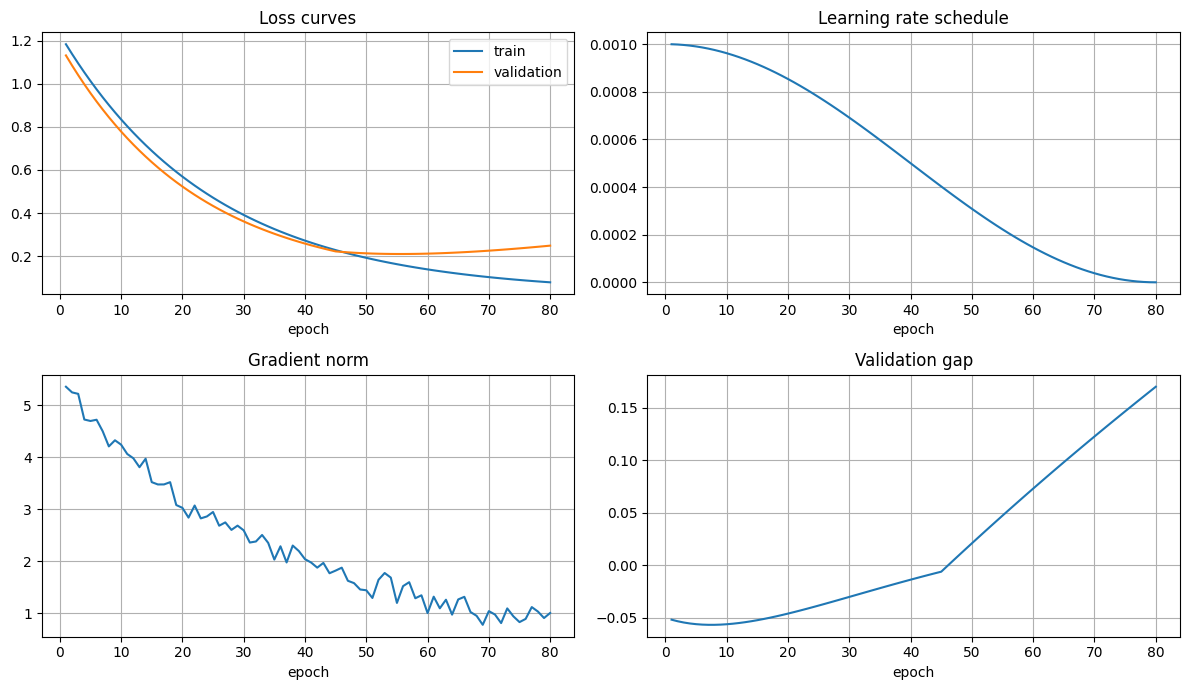

In [30]:
epochs = np.arange(1, 81)
train_loss = 1.2*np.exp(-epochs/25)+0.03
val_loss = 1.1*np.exp(-epochs/22)+0.08+0.004*np.maximum(epochs-45,0)
grad_norm = 5*np.exp(-epochs/35)+0.4 + 0.15*rng.normal(size=len(epochs))
lr_curve = 0.001 * 0.5*(1+np.cos(np.pi*epochs/epochs.max()))

fig, axes = plt.subplots(2,2,figsize=(12,7))
axes[0,0].plot(epochs, train_loss, label='train')
axes[0,0].plot(epochs, val_loss, label='validation')
axes[0,0].set_title('Loss curves'); axes[0,0].legend()
axes[0,1].plot(epochs, lr_curve)
axes[0,1].set_title('Learning rate schedule')
axes[1,0].plot(epochs, grad_norm)
axes[1,0].set_title('Gradient norm')
axes[1,1].plot(epochs, val_loss-train_loss)
axes[1,1].set_title('Validation gap')
for ax in axes.ravel():
    ax.set_xlabel('epoch')
plt.tight_layout()


**What this diagnostic view shows:** the model may still be training while validation starts worsening. The learning rate may be decaying correctly, but gradient norm spikes can reveal instability. This is the level of evidence needed before changing optimizer.


## Module 06 Summary

Backpropagation gives gradients. Optimizers decide how to use those gradients. Plain gradient descent uses the current gradient directly. Mini-batches make gradients noisy but efficient. Momentum smooths movement through ravines. AdaGrad, RMSProp, and Adam adapt step sizes per parameter. AdamW handles weight decay more cleanly for adaptive optimization. Schedules and warmup control learning rate over time. Gradient clipping prevents unusually large gradients from destroying training.


## References Used for This Module

* CS231n training neural networks notes: https://cs231n.github.io/neural-networks-3/
* Dive into Deep Learning, optimization chapter: https://d2l.ai/chapter_optimization/
* Deep Learning book, optimization chapter: https://www.deeplearningbook.org/contents/optimization.html
* PyTorch optimizer and scheduler documentation: https://docs.pytorch.org/docs/stable/optim.html
* PyTorch AdamW documentation: https://docs.pytorch.org/docs/stable/generated/torch.optim.AdamW.html
* Visual optimizer explanation videos reviewed for teaching style: YouTube results for SGD, Momentum, RMSProp, Adam optimizer visual explanations.
